# Backtesting Engine

A day-by-day portfolio simulator written from scratch, built to test rebalancing rules on a thematic equity portfolio without the look-ahead bias that vectorised backtests make easy to introduce.

I wrote this because the alternative was to trust a library. Most backtesting packages are fine, but they hide the two decisions that actually determine whether a backtest means anything: what information the strategy is allowed to see at each point in time, and what it costs to trade. Both are visible in this engine, and both are configurable.

The portfolio under test comes from a separate piece of work, an investment thesis on the data centre buildout driven by AI compute demand. The weights are taken as given here. This notebook is about the simulation machinery, not the thesis.

## What the engine does

It holds positions in shares rather than weights, marks the book to market every trading day, charges a cost on every fill, and records each trade so the resulting P&L can be audited line by line. Five rebalancing rules are implemented against a common interface, and the last two sections compare them and test how sensitive the ranking is to the cost assumption.

## Contents

1. [Setup and configuration](#1)
2. [Data acquisition](#2)
3. [Core backtesting engine](#3)
4. [Strategy definitions](#4)
5. [Performance analytics](#5)
6. [Risk analytics](#6)
7. [Visualisation](#7)
8. [Primary backtest](#8)
9. [Strategy comparison and cost sensitivity](#9)
10. [Export](#10)


<a id='1'></a>
## 1. Setup and configuration

Every parameter that could change a result lives in this section rather than being scattered through the notebook. That is a reproducibility requirement, not housekeeping: if the transaction cost assumption is written inline at the point of use, nobody reading the notebook can tell what the headline Sharpe ratio was conditioned on.

The risk-free rate is set at 5%, roughly the Treasury bill yield over the sample. It enters only the Sharpe ratio and the Sortino ratio. It does not accrue on cash balances inside the engine, which matters for one of the strategies and is discussed in section 4.

### Where the weights come from, and what that implies

The target weights in the next cell were not produced by this repository. They come from the tangency portfolio reported in the accompanying investment thesis, which was computed in an external portfolio tool on monthly returns from 2019 to 2024.

That matters for interpreting everything that follows. The backtest runs from 2020 to 2025, so roughly five of its six years overlap the window the weights were optimised on. A tangency portfolio is, by construction, the portfolio that would have done best over its estimation window, so backtesting it over that same window measures the fit, not the strategy. The headline performance in section 8 should be read as an in-sample figure. The comparisons between rebalancing rules in section 9 are less affected, because every rule starts from the same weights and the question there is how execution and rebalancing change the outcome, not whether the weights were good.

The engine itself is indifferent to where weights come from. Feeding it weights estimated only on data before 2020 would make the headline figure an honest out-of-sample number, and that is the first change I would make.

In [1]:
# === Core Dependencies ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec
from scipy import stats
from scipy.optimize import minimize
import yfinance as yf
from datetime import datetime, timedelta
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple, Callable
import warnings
import os
import json

warnings.filterwarnings('ignore')

# === Plot Style ===
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (14, 7),
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'figure.dpi': 100,
})

# Color palette for consistent charts
COLORS = {
    'primary': '#1f77b4',
    'secondary': '#ff7f0e',
    'accent': '#2ca02c',
    'danger': '#d62728',
    'muted': '#7f7f7f',
    'palette': ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
                '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf',
                '#aec7e8', '#ffbb78', '#98df8a', '#ff9896', '#c5b0d5']
}

print('Setup complete.')

Setup complete.


In [2]:
# === Portfolio Configuration ===
# Target weights are taken from the investment thesis document (p.14), where they
# were produced by an external portfolio tool rather than by code in this repository.
# They are an INPUT here, not something this notebook estimates. See the note in
# section 1 on why that makes the backtest below partly in-sample.

PORTFOLIO_CONFIG = {
    'name': 'AI Data Center Infrastructure',
    'benchmark': 'SPY',  # S&P 500 ETF as benchmark
    'risk_free_rate': 0.05,  # ~5% (current T-bill proxy)
    'initial_capital': 100_000,
    'start_date': '2020-01-01',
    'end_date': '2025-12-31',
}

# Tangency weights as reported in the thesis document
TARGET_WEIGHTS = {
    'IRM':   0.2733,   # Iron Mountain — defensive anchor, high dividend
    'ANET':  0.2622,   # Arista Networks — AI networking growth
    'VRT':   0.1532,   # Vertiv — power/cooling, high-growth
    'ETN':   0.0937,   # Eaton — electrical infrastructure
    'GDS':   0.0462,   # GDS Holdings — China/Asia data centers
    'JCI':   0.0397,   # Johnson Controls — HVAC/building systems
    'CAT':   0.0343,   # Caterpillar — backup power/industrial
    'VNET':  0.0305,   # 21Vianet — China colocation
    'GNRC':  0.0244,   # Generac — backup power generation
    'AMT':   0.0210,   # American Tower — tower REIT + data centers
    'MRVL':  0.0110,   # Marvell — networking semiconductors
    'SBGSY': 0.0054,   # Schneider Electric — power distribution
    'EQIX':  0.0031,   # Equinix — global colocation REIT
    'DLR':   0.0020,   # Digital Realty — wholesale data center REIT
}

# Validate weights sum to ~1.0
total_weight = sum(TARGET_WEIGHTS.values())
assert abs(total_weight - 1.0) < 0.01, f'Weights sum to {total_weight:.4f}, expected ~1.0'
print(f'Portfolio: {len(TARGET_WEIGHTS)} positions, weights sum = {total_weight:.4f}')
print(f'Top 3 holdings: {sum(list(TARGET_WEIGHTS.values())[:3]):.1%} of portfolio')

Portfolio: 14 positions, weights sum = 1.0000
Top 3 holdings: 68.9% of portfolio


<a id='2'></a>
## 2. Data acquisition

Prices come from a local CSV snapshot rather than a live API call. This is deliberate. A notebook that downloads fresh data on every run produces different numbers every time it is executed, which means the figures committed alongside the code and the code itself can silently diverge. Freezing the sample makes the repository reproducible: anyone cloning it gets the series I used, not whatever the vendor returns on the day they run it.

I use split- and dividend-adjusted closes, so the return series is a total return. On a portfolio this heavy in REITs the distinction is not cosmetic. Iron Mountain and American Tower together carry roughly 29% of the weight and both yield meaningfully, so a price-return series would understate the portfolio's realised return by a few percentage points a year while leaving the benchmark comparison looking superficially reasonable.

The loader falls back to a live download if no snapshot is present, so the notebook still runs on a clean checkout before the data has been fetched.


In [3]:
class DataLoader:
    """
    Handles price data acquisition with local caching.
    Uses adjusted close prices to account for splits and dividends.
    """
    
    def __init__(self, cache_dir: str = './data_cache'):
        self.cache_dir = cache_dir
        os.makedirs(cache_dir, exist_ok=True)
    
    def fetch_prices(self, tickers: List[str], start: str, end: str,
                     use_cache: bool = True) -> pd.DataFrame:
        """
        Fetch adjusted close prices for a list of tickers.
        Returns a DataFrame with DatetimeIndex and ticker columns.
        """
        # Prefer the frozen snapshot written by fetch_data.py. Freezing the
        # sample is what makes this notebook reproducible: a live download on
        # every execution means the committed figures and the code that
        # produced them drift apart, silently.
        snapshot = os.path.join(self.cache_dir, 'prices_daily.csv')
        if use_cache and os.path.exists(snapshot):
            prices = pd.read_csv(snapshot, index_col=0, parse_dates=True)
            available = [t for t in tickers if t in prices.columns]
            missing = [t for t in tickers if t not in prices.columns]
            prices = prices.loc[start:end, available]
            print(f'Loaded frozen snapshot: {len(available)}/{len(tickers)} tickers, '
                  f'{len(prices)} trading days '
                  f'({prices.index[0].date()} to {prices.index[-1].date()})')
            if missing:
                print(f'  not in snapshot: {missing}')
            return prices.ffill().bfill()

        cache_file = os.path.join(
            self.cache_dir,
            f"prices_{'_'.join(sorted(tickers)[:5])}_{start}_{end}.csv"
        )

        if use_cache and os.path.exists(cache_file):
            print(f'Loading cached data from {cache_file}')
            prices = pd.read_csv(cache_file, index_col=0, parse_dates=True)
            return prices
        
        print(f'Downloading data for {len(tickers)} tickers from {start} to {end}...')
        
        # Download all tickers at once for efficiency
        raw = yf.download(tickers, start=start, end=end, auto_adjust=True)
        
        # yfinance returns MultiIndex columns for multiple tickers
        if isinstance(raw.columns, pd.MultiIndex):
            prices = raw['Close'].copy()
        else:
            # Single ticker case
            prices = raw[['Close']].copy()
            prices.columns = tickers
        
        # Forward-fill then back-fill small gaps (weekends/holidays already excluded)
        prices = prices.ffill().bfill()
        
        # Report any issues
        missing = prices.isnull().sum()
        if missing.any():
            print(f'WARNING: Missing data after fill:\n{missing[missing > 0]}')
        
        # Cache locally
        prices.to_csv(cache_file)
        print(f'Data cached to {cache_file}')
        print(f'Date range: {prices.index[0].date()} to {prices.index[-1].date()}')
        print(f'Shape: {prices.shape[0]} trading days x {prices.shape[1]} tickers')
        
        return prices
    
    def compute_returns(self, prices: pd.DataFrame,
                        method: str = 'log') -> pd.DataFrame:
        """
        Compute returns from price series.
        method: 'log' for log returns, 'simple' for arithmetic returns.
        """
        if method == 'log':
            return np.log(prices / prices.shift(1)).dropna()
        else:
            return prices.pct_change().dropna()


# === Load Data ===
loader = DataLoader()

all_tickers = list(TARGET_WEIGHTS.keys()) + [PORTFOLIO_CONFIG['benchmark']]
prices = loader.fetch_prices(
    tickers=all_tickers,
    start=PORTFOLIO_CONFIG['start_date'],
    end=PORTFOLIO_CONFIG['end_date'],
    use_cache=True,   # snapshot first, live download only if absent
)

# Separate benchmark
benchmark_prices = prices[[PORTFOLIO_CONFIG['benchmark']]].copy()
asset_prices = prices.drop(columns=[PORTFOLIO_CONFIG['benchmark']])

# Quick sanity check
print(f'\nAsset prices shape: {asset_prices.shape}')
print(f'Date range: {asset_prices.index[0].date()} → {asset_prices.index[-1].date()}')
asset_prices.tail(3)

Loaded frozen snapshot: 15/15 tickers, 1507 trading days (2020-01-02 to 2025-12-30)

Asset prices shape: (1507, 14)
Date range: 2020-01-02 → 2025-12-30


,IRM,ANET,VRT,ETN,GDS,JCI,CAT,VNET,GNRC,AMT,MRVL,SBGSY,EQIX,DLR
Date,,,,,,,,,,,,,,
2025-12-26,80.151932,131.839996,167.464203,319.497375,35.400002,121.010338,579.458923,8.69,140.559998,169.513290,86.194641,54.603455,751.833679,151.900406
2025-12-29,80.777588,134.149994,165.505569,318.783356,34.650002,120.663353,575.095642,8.64,138.479996,170.599960,85.615631,54.692097,753.508179,152.527557
2025-12-30,81.491226,132.440002,164.226456,318.198212,34.599998,119.899971,573.882996,8.48,137.860001,171.463486,86.613945,54.603455,758.147400,153.252716


<a id='3'></a>
## 3. Core backtesting engine

There are two ways to write this. The fast way is vectorised: build a matrix of weights, multiply it by a matrix of returns, sum along the rows. It runs in milliseconds, and it is wrong in a way that is hard to detect, because nothing in the arithmetic stops a weight indexed at time $t$ from having been computed using information from $t+1$. Look-ahead bias then has to be ruled out by discipline, and discipline fails quietly.

I took the slow route. The engine iterates one trading day at a time and passes the strategy function only `prices.iloc[:i+1]`. Information that does not exist yet cannot be handed in, so look-ahead is prevented by construction rather than by care. The cost is roughly three orders of magnitude in speed, which over six years of daily data is a few seconds. That is a trade I will make every time.

### State the engine carries

The book is held as share counts plus a residual cash balance, not as weights. A weight-based simulator implicitly assumes assets are infinitely divisible and that rebalancing is frictionless and instantaneous. Holding shares forces the leftovers into the simulation: after a rebalance the cash that could not be deployed sits idle, and `allow_fractional_shares` switches between the two regimes so the effect can be measured rather than assumed away. At $100,000 of capital, fractional shares are realistic for most retail and all institutional execution, so it defaults to `True`; setting it `False` shows what the same strategy would have done under whole-share constraints.

### Execution model

Each rebalance computes the trade list, then executes sells before buys so that proceeds are available to fund the purchases. Without that ordering the engine would need to permit a negative cash balance during the rebalance, which is an unintended and unmodelled margin loan.

Costs enter in two places, because they are two different phenomena. Slippage is applied to the execution price and is signed: a buy fills above the close, a sell below it. Commission is applied to the notional and is unsigned. With the defaults of 5 bps slippage and 10 bps commission, a round trip costs about 30 bps. Keeping them separate matters because they scale differently with trade size, and because the sensitivity analysis in section 9 varies one of them.

Trades smaller than `min_trade_value` are skipped. Without this the engine churns through dozens of sub-dollar corrections at every rebalance, each paying the fixed component of cost, which is not how anyone actually trades.

### Known limitations

Two are worth stating plainly rather than leaving for a reader to find.

Cash earns nothing. The engine holds idle balances at zero interest while the Sharpe ratio is computed against a 5% risk-free rate. Any strategy that deliberately sits in cash is therefore penalised twice, once for the foregone equity return and once for a risk-free return it should have earned but does not. The volatility-targeted strategy in section 4 is the one this distorts, and the comparison in section 9 should be read with that in mind.

Missing prices are handled asymmetrically. Mark-to-market skips NaN entries, but the rebalance routine does not guard against them, so a ticker with a gap in its history could produce a NaN share count. The sample used here is complete across all names, so it does not bite, but it would on a universe with a delisting or a late listing.


In [4]:
@dataclass
class TradeRecord:
    """Single trade executed by the engine."""
    date: pd.Timestamp
    ticker: str
    shares: float       # positive = buy, negative = sell
    price: float
    cost: float         # transaction cost paid
    reason: str         # 'rebalance', 'signal', etc.


@dataclass
class BacktestConfig:
    """
    All parameters controlling backtest execution.
    Separating config from logic keeps experiments reproducible.
    """
    initial_capital: float = 100_000
    transaction_cost_bps: float = 10.0    # 10 bps (0.10%) per trade
    fixed_cost_per_trade: float = 0.0     # Fixed $ cost per trade
    slippage_bps: float = 5.0             # 5 bps market impact
    risk_free_rate: float = 0.05          # Annualized
    allow_fractional_shares: bool = True  # True for realism at small scale
    min_trade_value: float = 50.0         # Don't execute trades < $50


class BacktestEngine:
    """
    Core backtesting engine.
    
    Design philosophy:
    - Event-driven: iterates day-by-day to model real execution
    - Strategy-agnostic: accepts any function that returns target weights
    - Tracks everything: full audit trail of positions, trades, values
    """
    
    def __init__(self, config: BacktestConfig = None):
        self.config = config or BacktestConfig()
        self.reset()
    
    def reset(self):
        """Clear all state for a fresh backtest run."""
        self.portfolio_values = []       # Daily portfolio NAV
        self.cash_history = []           # Daily cash balance
        self.positions_history = []      # Daily positions snapshot
        self.weight_history = []         # Daily actual weights
        self.trades: List[TradeRecord] = []
        self.rebalance_dates = []        # Dates where rebalancing occurred
        self._current_shares = {}        # Ticker -> shares held
        self._cash = self.config.initial_capital
    
    def run(self,
            prices: pd.DataFrame,
            strategy_fn: Callable,
            strategy_params: dict = None) -> pd.DataFrame:
        """
        Execute a backtest.
        
        Parameters
        ----------
        prices : DataFrame
            Daily adjusted close prices (DatetimeIndex, ticker columns).
        strategy_fn : callable
            Function(date, prices_so_far, current_weights, params) -> target_weights dict.
            Return None to skip rebalancing on that day.
        strategy_params : dict
            Passed to strategy_fn each call.
        
        Returns
        -------
        DataFrame with columns: ['date', 'portfolio_value', 'cash', 'benchmark']
        """
        self.reset()
        params = strategy_params or {}
        tickers = list(prices.columns)
        
        # Initialize positions to zero shares
        for ticker in tickers:
            self._current_shares[ticker] = 0.0
        
        for i, date in enumerate(prices.index):
            current_prices = prices.loc[date]
            
            # --- Mark to Market ---
            holdings_value = sum(
                self._current_shares.get(t, 0) * current_prices[t]
                for t in tickers
                if not np.isnan(current_prices[t])
            )
            total_value = holdings_value + self._cash
            
            # --- Compute current weights ---
            current_weights = {}
            for t in tickers:
                pos_val = self._current_shares.get(t, 0) * current_prices[t]
                current_weights[t] = pos_val / total_value if total_value > 0 else 0.0
            
            # --- Ask strategy for target weights ---
            prices_so_far = prices.iloc[:i+1]
            target_weights = strategy_fn(date, prices_so_far, current_weights, params)
            
            # --- Rebalance if strategy returns weights ---
            if target_weights is not None:
                self._rebalance(date, current_prices, target_weights, total_value, tickers)
                self.rebalance_dates.append(date)
                
                # Recalculate after rebalancing
                holdings_value = sum(
                    self._current_shares.get(t, 0) * current_prices[t]
                    for t in tickers
                )
                total_value = holdings_value + self._cash
            
            # --- Record state ---
            self.portfolio_values.append({'date': date, 'value': total_value})
            self.cash_history.append(self._cash)
            self.positions_history.append(dict(self._current_shares))
            self.weight_history.append(dict(current_weights))
        
        # Build results DataFrame
        results = pd.DataFrame(self.portfolio_values).set_index('date')
        results.columns = ['portfolio_value']
        results['cash'] = self.cash_history
        results['daily_return'] = results['portfolio_value'].pct_change()
        
        return results
    
    def _rebalance(self, date, current_prices, target_weights, total_value, tickers):
        """
        Execute trades to move from current positions to target weights.
        Sells first (to free cash), then buys.
        """
        orders = []
        
        for ticker in tickers:
            target_w = target_weights.get(ticker, 0.0)
            target_value = total_value * target_w
            current_value = self._current_shares.get(ticker, 0) * current_prices[ticker]
            trade_value = target_value - current_value
            
            # Skip tiny trades to avoid excessive costs
            if abs(trade_value) < self.config.min_trade_value:
                continue
            
            price_with_slippage = current_prices[ticker] * (
                1 + np.sign(trade_value) * self.config.slippage_bps / 10_000
            )
            
            shares_to_trade = trade_value / price_with_slippage
            if not self.config.allow_fractional_shares:
                shares_to_trade = int(shares_to_trade)
            
            if shares_to_trade != 0:
                orders.append((ticker, shares_to_trade, price_with_slippage, trade_value))
        
        # Execute sells first (frees up cash)
        sells = [(t, s, p, v) for t, s, p, v in orders if s < 0]
        buys  = [(t, s, p, v) for t, s, p, v in orders if s > 0]
        
        for ticker, shares, price, value in sells + buys:
            cost = (
                abs(value) * self.config.transaction_cost_bps / 10_000
                + self.config.fixed_cost_per_trade
            )
            
            # Update positions and cash
            self._current_shares[ticker] = self._current_shares.get(ticker, 0) + shares
            self._cash -= (shares * price) + cost
            
            # Log the trade
            self.trades.append(TradeRecord(
                date=date, ticker=ticker, shares=shares,
                price=price, cost=cost, reason='rebalance'
            ))
    
    def get_trade_log(self) -> pd.DataFrame:
        """Return all trades as a DataFrame for analysis."""
        if not self.trades:
            return pd.DataFrame()
        return pd.DataFrame([
            {'date': t.date, 'ticker': t.ticker, 'shares': t.shares,
             'price': t.price, 'cost': t.cost, 'notional': abs(t.shares * t.price),
             'reason': t.reason}
            for t in self.trades
        ])


print('BacktestEngine loaded.')

BacktestEngine loaded.


<a id='4'></a>
## 4. Strategy definitions

Every strategy implements the same interface:

```python
def strategy(date, prices_so_far, current_weights, params) -> Optional[Dict[str, float]]
```

It returns `None` to do nothing, or a dictionary of target weights to trigger a rebalance. The engine knows nothing else about it. That separation is what makes the comparison in section 9 fair: all five rules run through identical execution, costs and accounting, so any difference in results comes from the rule and not from the plumbing.

I implemented five.

### Buy and hold

Buys once on the first day, then never trades again. This is the baseline that every other strategy has to beat, and it is the one with the lowest possible transaction costs. Any rule that cannot clear it is paying for activity that does not earn its keep.

### Calendar rebalancing

Returns to the target weights on a fixed schedule, monthly through annually. This is what most institutional mandates actually specify, so it is the realistic comparator rather than a straw man. Its appeal is that it is mechanical and auditable. Its weakness is that it trades whether or not the portfolio has drifted, so in a quiet quarter it pays costs for nothing.

### Threshold rebalancing

Rebalances only when some position has drifted more than a set distance from its target, here 5% in absolute weight. This is the no-trade region idea: when trading is costly, the optimal policy is not to track the target continuously but to tolerate a band around it and act only at the edges. Davis and Norman (1990) derive the continuous-time version of this result for a portfolio with proportional transaction costs, where the optimal policy is exactly a no-trade interval around the Merton weight.

The band width here is chosen, not solved. That is worth being honest about: 5% is a free parameter, and the fact that it was picked rather than derived is precisely the kind of researcher degree of freedom that makes backtested results look better than live ones.

### Momentum overlay

Applies a calendar trigger, then zeroes out any name whose trailing 63-day return is negative and redistributes that weight proportionally across the survivors.

The redistribution step is the part to watch. The portfolio is already concentrated, with Iron Mountain and Arista at roughly 27% and 26%. In a drawdown where most names are negative, the surviving positions absorb all the removed weight, and a portfolio with a 15% notional cap in its original optimisation can end up with a single position well above that. The rule reduces the number of names it is exposed to at exactly the moment correlations are rising, which is the opposite of what diversification is for.

### Volatility targeting

Estimates realised portfolio volatility over a 63-day window and scales exposure by the ratio of target to realised, clipped to the interval $[0.25, 1.0]$.

Three things about this implementation are worth drawing out.

The scalar is capped at 1.0, so the rule can only de-risk, never lever. That makes it an asymmetric overlay rather than a true volatility target. A symmetric version would hold average exposure near 1 and would behave quite differently in the calm periods that dominate this sample.

Realised volatility is computed by applying the fixed target weights to the recent return matrix, not the portfolio's actual drifted weights. This is a reasonable approximation and it avoids a feedback loop between the scalar and the drift, but it is an approximation.

Finally, the theoretical case for this rule is stronger than its implementation here can show. By Jensen's inequality, holding average variance fixed, a portfolio with constant variance compounds faster than one with fluctuating variance, and the gap is approximately $\tfrac{1}{2}\operatorname{Var}(\sigma_t^2)$ in geometric return. Capturing that requires no return forecasting ability at all, only that volatility is forecastable, which it reliably is. But because the engine pays no interest on the cash this rule parks, the measured result understates the strategy by the risk-free rate times the average time spent de-risked. The honest reading of section 9 is that volatility targeting is handicapped here.


In [5]:
# ============================================================
# STRATEGY 1: Calendar Rebalancing
# Rebalance to fixed target weights on a schedule.
# ============================================================

def strategy_calendar_rebalance(date, prices_so_far, current_weights, params):
    """
    Rebalance to target weights at a fixed frequency.
    
    params:
        'target_weights': dict of ticker -> weight
        'frequency': 'monthly', 'quarterly', 'annually'
        'rebal_day': int, day of month to rebalance (default: 1)
    """
    target_weights = params['target_weights']
    frequency = params.get('frequency', 'monthly')
    
    # First trading day: always rebalance to establish positions
    if len(prices_so_far) <= 1:
        return target_weights
    
    prev_date = prices_so_far.index[-2]
    
    if frequency == 'monthly':
        trigger = date.month != prev_date.month
    elif frequency == 'quarterly':
        trigger = (date.month != prev_date.month) and (date.month in [1, 4, 7, 10])
    elif frequency == 'semi_annual':
        trigger = (date.month != prev_date.month) and (date.month in [1, 7])
    elif frequency == 'annually':
        trigger = date.year != prev_date.year
    else:
        trigger = False
    
    return target_weights if trigger else None


# ============================================================
# STRATEGY 2: Threshold (Drift) Rebalancing
# Rebalance only when any position drifts beyond a tolerance band.
# ============================================================

def strategy_threshold_rebalance(date, prices_so_far, current_weights, params):
    """
    Rebalance when any position deviates from target by > threshold.
    
    params:
        'target_weights': dict
        'threshold': float (e.g., 0.05 = 5% absolute drift)
    """
    target_weights = params['target_weights']
    threshold = params.get('threshold', 0.05)
    
    if len(prices_so_far) <= 1:
        return target_weights
    
    # Check if any position has drifted beyond threshold
    for ticker, target_w in target_weights.items():
        current_w = current_weights.get(ticker, 0.0)
        if abs(current_w - target_w) > threshold:
            return target_weights
    
    return None


# ============================================================
# STRATEGY 3: Momentum Overlay
# Adjust weights based on trailing momentum signals.
# If an asset has negative trailing return, reduce weight to zero
# and redistribute to positive-momentum assets.
# ============================================================

def strategy_momentum_overlay(date, prices_so_far, current_weights, params):
    """
    Calendar rebalance + momentum filter.
    Assets with negative trailing returns are zeroed out;
    their weight is redistributed proportionally.
    
    params:
        'target_weights': dict
        'frequency': str
        'lookback_days': int (e.g., 63 for ~3 months)
    """
    target_weights = params['target_weights']
    frequency = params.get('frequency', 'monthly')
    lookback = params.get('lookback_days', 63)
    
    if len(prices_so_far) <= 1:
        return target_weights
    
    prev_date = prices_so_far.index[-2]
    
    # Check calendar trigger
    if frequency == 'monthly':
        trigger = date.month != prev_date.month
    elif frequency == 'quarterly':
        trigger = (date.month != prev_date.month) and (date.month in [1, 4, 7, 10])
    else:
        trigger = False
    
    if not trigger:
        return None
    
    # Not enough history for momentum signal
    if len(prices_so_far) < lookback:
        return target_weights
    
    # Compute trailing returns
    trailing_returns = (
        prices_so_far.iloc[-1] / prices_so_far.iloc[-lookback] - 1
    )
    
    # Filter: zero out negative-momentum assets
    adjusted = {}
    for ticker, w in target_weights.items():
        if ticker in trailing_returns and trailing_returns[ticker] > 0:
            adjusted[ticker] = w
        else:
            adjusted[ticker] = 0.0
    
    # Redistribute to maintain full investment
    total = sum(adjusted.values())
    if total > 0:
        adjusted = {t: w / total for t, w in adjusted.items()}
    else:
        # All negative momentum — hold cash (return tiny weights)
        adjusted = {t: 0.0 for t in target_weights}
    
    return adjusted


# ============================================================
# STRATEGY 4: Volatility-Targeted
# Scale portfolio exposure to target a specific annualized vol.
# ============================================================

def strategy_vol_target(date, prices_so_far, current_weights, params):
    """
    Calendar rebalance with a volatility scalar.
    If realized vol > target, scale down exposure (hold cash).
    If realized vol < target, scale up (but cap at 1.0x).
    
    params:
        'target_weights': dict
        'frequency': str
        'target_vol': float (e.g., 0.20 = 20% annualized)
        'vol_lookback': int (trading days)
    """
    target_weights = params['target_weights']
    frequency = params.get('frequency', 'monthly')
    target_vol = params.get('target_vol', 0.20)
    vol_lookback = params.get('vol_lookback', 63)
    
    if len(prices_so_far) <= 1:
        return target_weights
    
    prev_date = prices_so_far.index[-2]
    if frequency == 'monthly':
        trigger = date.month != prev_date.month
    elif frequency == 'quarterly':
        trigger = (date.month != prev_date.month) and (date.month in [1, 4, 7, 10])
    else:
        trigger = False
    
    if not trigger:
        return None
    
    if len(prices_so_far) < vol_lookback:
        return target_weights
    
    # Estimate portfolio realized vol using weighted returns
    recent = prices_so_far.iloc[-vol_lookback:]
    rets = recent.pct_change().dropna()
    
    # Portfolio return using current target weights
    w = np.array([target_weights.get(c, 0) for c in rets.columns])
    port_rets = rets.values @ w
    realized_vol = np.std(port_rets) * np.sqrt(252)
    
    # Scale factor: target_vol / realized_vol, capped at [0.25, 1.0]
    if realized_vol > 0:
        scale = min(1.0, max(0.25, target_vol / realized_vol))
    else:
        scale = 1.0
    
    scaled_weights = {t: w * scale for t, w in target_weights.items()}
    return scaled_weights


# ============================================================
# STRATEGY 5: Buy-and-Hold (baseline)
# Invest on day 1 and never rebalance.
# ============================================================

def strategy_buy_and_hold(date, prices_so_far, current_weights, params):
    """Buy once on the first day, then hold forever."""
    if len(prices_so_far) <= 1:
        return params['target_weights']
    return None


print('5 strategies loaded: calendar, threshold, momentum, vol_target, buy_and_hold')

5 strategies loaded: calendar, threshold, momentum, vol_target, buy_and_hold


<a id='5'></a>
## 5. Performance analytics

### Sharpe ratio

Computed as $\sqrt{252}\,\bar{r}_e / s_{r}$ on daily excess returns. The $\sqrt{252}$ is not a convention, it is a consequence of assuming returns are serially independent so that variance accumulates linearly in time. Real strategy returns are autocorrelated, and Lo (2002) shows the correct scaling factor depends on the entire autocorrelation structure of the series:

$$\mathrm{SR}(q) = \frac{q}{\sqrt{q + 2\sum_{k=1}^{q-1}(q-k)\rho_k}} \cdot \mathrm{SR}$$

For positively autocorrelated returns the denominator exceeds $\sqrt{q}$, so naive annualisation overstates the Sharpe ratio. Momentum and illiquidity exposures both produce positive autocorrelation, which means this bias runs in the flattering direction for exactly the strategies most likely to be presented as successful. I report the unadjusted figure here and treat it as an upper bound.

### Geometric against arithmetic return

CAGR is reported separately from the mean return rather than as a restatement of it, because they answer different questions. The arithmetic mean describes the average year. The geometric mean describes what actually compounded, and the gap between them is approximately $\sigma^2 / 2$. For a portfolio running 25% annualised volatility that is roughly 3 percentage points a year, which is large enough that quoting the arithmetic figure as "the return" misleads. The same quantity is the volatility drag that gives the strategy in section 4 its theoretical justification.

### Sortino ratio

Replaces total volatility in the denominator with downside deviation, on the argument that upside dispersion is not a risk. This is intuitive but it comes at a statistical cost: the downside semi-deviation is estimated from roughly half the sample, so its standard error is larger, and the resulting ratio is noisier than the Sharpe ratio it is meant to improve on. I report both rather than choosing.

### Maximum drawdown

$$\mathrm{MDD} = \min_t \left( \frac{V_t}{\max_{s \le t} V_s} - 1 \right)$$

Drawdown is a path statistic, not a moment of the return distribution. Two return series with identical mean, variance, skew and kurtosis can have very different maximum drawdowns depending on the order in which the returns arrive. This has two consequences that are routinely ignored: maximum drawdown cannot be annualised, and it cannot be compared across samples of different length, because a longer sample has more opportunity to produce a worse one. Comparing the drawdown of a six-year backtest against a twenty-year benchmark history is not a like-for-like comparison.


In [6]:
class PerformanceAnalytics:
    """
    Compute portfolio performance metrics from a return series.
    All methods are static for reusability.
    """
    
    @staticmethod
    def total_return(values: pd.Series) -> float:
        return values.iloc[-1] / values.iloc[0] - 1
    
    @staticmethod
    def cagr(values: pd.Series) -> float:
        """Compound annual growth rate."""
        n_years = (values.index[-1] - values.index[0]).days / 365.25
        if n_years <= 0:
            return 0.0
        return (values.iloc[-1] / values.iloc[0]) ** (1 / n_years) - 1
    
    @staticmethod
    def annualized_vol(returns: pd.Series) -> float:
        return returns.std() * np.sqrt(252)
    
    @staticmethod
    def sharpe_ratio(returns: pd.Series, rf_rate: float = 0.05) -> float:
        """Annualized Sharpe ratio."""
        excess = returns - rf_rate / 252
        if excess.std() == 0:
            return 0.0
        return (excess.mean() / excess.std()) * np.sqrt(252)
    
    @staticmethod
    def sortino_ratio(returns: pd.Series, rf_rate: float = 0.05) -> float:
        """Sortino ratio: penalizes only downside volatility."""
        excess = returns - rf_rate / 252
        downside = excess[excess < 0]
        downside_std = downside.std() * np.sqrt(252)
        if downside_std == 0:
            return 0.0
        ann_excess = excess.mean() * 252
        return ann_excess / downside_std
    
    @staticmethod
    def max_drawdown(values: pd.Series) -> Tuple[float, pd.Timestamp, pd.Timestamp]:
        """
        Maximum drawdown with peak and trough dates.
        Returns: (drawdown_pct, peak_date, trough_date)
        """
        cummax = values.cummax()
        drawdown = (values - cummax) / cummax
        trough_idx = drawdown.idxmin()
        peak_idx = values.loc[:trough_idx].idxmax()
        return drawdown.min(), peak_idx, trough_idx
    
    @staticmethod
    def calmar_ratio(values: pd.Series) -> float:
        """CAGR / |Max Drawdown| — measures return per unit of tail risk."""
        c = PerformanceAnalytics.cagr(values)
        mdd, _, _ = PerformanceAnalytics.max_drawdown(values)
        return c / abs(mdd) if mdd != 0 else 0.0
    
    @staticmethod
    def win_rate(returns: pd.Series) -> float:
        return (returns > 0).mean()
    
    @staticmethod
    def profit_factor(returns: pd.Series) -> float:
        """Sum of gains / sum of losses."""
        gains = returns[returns > 0].sum()
        losses = abs(returns[returns < 0].sum())
        return gains / losses if losses > 0 else np.inf
    
    @staticmethod
    def tail_ratio(returns: pd.Series) -> float:
        """95th percentile gain / |5th percentile loss|."""
        p95 = returns.quantile(0.95)
        p05 = abs(returns.quantile(0.05))
        return p95 / p05 if p05 > 0 else np.inf
    
    @staticmethod
    def var_historic(returns: pd.Series, confidence: float = 0.95) -> float:
        """Historical Value-at-Risk at given confidence level."""
        return returns.quantile(1 - confidence)
    
    @staticmethod
    def cvar_historic(returns: pd.Series, confidence: float = 0.95) -> float:
        """Conditional VaR (Expected Shortfall): mean loss beyond VaR."""
        var = PerformanceAnalytics.var_historic(returns, confidence)
        return returns[returns <= var].mean()
    
    @staticmethod
    def information_ratio(returns: pd.Series, benchmark_returns: pd.Series) -> float:
        """Active return / tracking error."""
        active = returns - benchmark_returns
        te = active.std() * np.sqrt(252)
        if te == 0:
            return 0.0
        return (active.mean() * 252) / te
    
    @staticmethod
    def beta(returns: pd.Series, benchmark_returns: pd.Series) -> float:
        """Portfolio beta relative to benchmark."""
        aligned = pd.concat([returns, benchmark_returns], axis=1).dropna()
        if len(aligned) < 2:
            return np.nan
        cov = np.cov(aligned.iloc[:, 0], aligned.iloc[:, 1])
        return cov[0, 1] / cov[1, 1] if cov[1, 1] != 0 else np.nan
    
    @staticmethod
    def alpha_jensen(returns: pd.Series, benchmark_returns: pd.Series,
                     rf_rate: float = 0.05) -> float:
        """Jensen's alpha: annualized excess return not explained by beta."""
        b = PerformanceAnalytics.beta(returns, benchmark_returns)
        port_ann = returns.mean() * 252
        bench_ann = benchmark_returns.mean() * 252
        return port_ann - (rf_rate + b * (bench_ann - rf_rate))
    
    @staticmethod
    def turnover(trade_log: pd.DataFrame, portfolio_values: pd.Series) -> float:
        """
        Annualized portfolio turnover.
        Total notional traded / average portfolio value, annualized.
        """
        if trade_log.empty:
            return 0.0
        total_traded = trade_log['notional'].sum()
        avg_value = portfolio_values.mean()
        n_years = (portfolio_values.index[-1] - portfolio_values.index[0]).days / 365.25
        return (total_traded / avg_value) / n_years if n_years > 0 else 0.0
    
    @classmethod
    def full_report(cls, results: pd.DataFrame, benchmark_prices: pd.DataFrame,
                    trade_log: pd.DataFrame, rf_rate: float = 0.05) -> pd.DataFrame:
        """
        Generate a complete performance report comparing portfolio to benchmark.
        """
        port_vals = results['portfolio_value']
        port_rets = results['daily_return'].dropna()
        
        # Benchmark returns (align dates)
        bench = benchmark_prices.iloc[:, 0].reindex(port_vals.index).ffill()
        bench_rets = bench.pct_change().dropna()
        
        # Align
        common = port_rets.index.intersection(bench_rets.index)
        port_rets_a = port_rets.loc[common]
        bench_rets_a = bench_rets.loc[common]
        
        mdd_port, mdd_peak, mdd_trough = cls.max_drawdown(port_vals)
        mdd_bench, _, _ = cls.max_drawdown(bench)
        
        metrics = {
            'Total Return': f"{cls.total_return(port_vals):.2%}",
            'CAGR': f"{cls.cagr(port_vals):.2%}",
            'Annualized Volatility': f"{cls.annualized_vol(port_rets_a):.2%}",
            'Sharpe Ratio': f"{cls.sharpe_ratio(port_rets_a, rf_rate):.2f}",
            'Sortino Ratio': f"{cls.sortino_ratio(port_rets_a, rf_rate):.2f}",
            'Calmar Ratio': f"{cls.calmar_ratio(port_vals):.2f}",
            'Max Drawdown': f"{mdd_port:.2%}",
            'Max DD Period': f"{mdd_peak.date()} → {mdd_trough.date()}",
            'Daily Win Rate': f"{cls.win_rate(port_rets_a):.2%}",
            'Profit Factor': f"{cls.profit_factor(port_rets_a):.2f}",
            'Tail Ratio': f"{cls.tail_ratio(port_rets_a):.2f}",
            'VaR (95%)': f"{cls.var_historic(port_rets_a):.2%}",
            'CVaR (95%)': f"{cls.cvar_historic(port_rets_a):.2%}",
            'Beta': f"{cls.beta(port_rets_a, bench_rets_a):.2f}",
            'Jensen Alpha (ann.)': f"{cls.alpha_jensen(port_rets_a, bench_rets_a, rf_rate):.2%}",
            'Information Ratio': f"{cls.information_ratio(port_rets_a, bench_rets_a):.2f}",
            'Turnover (ann.)': f"{cls.turnover(trade_log, port_vals):.2f}x",
            'Total Transaction Costs': f"${trade_log['cost'].sum():,.2f}" if not trade_log.empty else '$0',
            'Number of Trades': len(trade_log),
            '--- Benchmark ---': '---',
            'Benchmark Total Return': f"{cls.total_return(bench):.2%}",
            'Benchmark CAGR': f"{cls.cagr(bench):.2%}",
            'Benchmark Volatility': f"{cls.annualized_vol(bench_rets_a):.2%}",
            'Benchmark Sharpe': f"{cls.sharpe_ratio(bench_rets_a, rf_rate):.2f}",
            'Benchmark Max DD': f"{mdd_bench:.2%}",
        }
        
        return pd.DataFrame.from_dict(metrics, orient='index', columns=['Value'])


print('PerformanceAnalytics loaded.')

PerformanceAnalytics loaded.


<a id='6'></a>
## 6. Risk analytics

Two things happen here that the headline metrics cannot show.

The drawdown decomposition identifies the worst episodes individually, with peak date, trough date and recovery date. The separation of depth from duration is the useful part. A 30% drawdown that recovers in four months and a 30% drawdown that takes three years to recover are the same number and completely different experiences, and only one of them survives contact with a client or a risk committee.

The rolling metrics re-estimate volatility, Sharpe ratio and beta over a moving window. The purpose is not to produce a better point estimate but to show how unstable the point estimate is. A full-sample Sharpe ratio of, say, 0.9 computed from six years of data is a single draw from a sampling distribution whose standard error is roughly $\sqrt{(1 + \mathrm{SR}^2/2)/T}$, which here is on the order of 0.4. Plotting the rolling estimate makes that uncertainty visible in a way a table never does, and it is a better defence against over-reading a backtest than any caveat written underneath one.


In [7]:
class RiskAnalytics:
    """Advanced risk metrics and decomposition."""
    
    @staticmethod
    def drawdown_series(values: pd.Series) -> pd.Series:
        """Compute the drawdown at each point in time."""
        cummax = values.cummax()
        return (values - cummax) / cummax
    
    @staticmethod
    def top_drawdowns(values: pd.Series, n: int = 5) -> pd.DataFrame:
        """Find the N largest drawdown periods with recovery info."""
        dd = RiskAnalytics.drawdown_series(values)
        drawdowns = []
        
        dd_copy = dd.copy()
        for _ in range(n):
            if dd_copy.min() >= 0:
                break
            trough_idx = dd_copy.idxmin()
            trough_val = dd_copy.min()
            
            # Find peak (start of drawdown)
            peak_idx = values.loc[:trough_idx].idxmax()
            
            # Find recovery (when value exceeds peak again)
            peak_val = values.loc[peak_idx]
            post_trough = values.loc[trough_idx:]
            recovered = post_trough[post_trough >= peak_val]
            recovery_idx = recovered.index[0] if len(recovered) > 0 else None
            
            duration = (trough_idx - peak_idx).days
            recovery_days = (recovery_idx - trough_idx).days if recovery_idx else None
            
            drawdowns.append({
                'Depth': trough_val,
                'Peak Date': peak_idx.date(),
                'Trough Date': trough_idx.date(),
                'Recovery Date': recovery_idx.date() if recovery_idx else 'Ongoing',
                'Days to Trough': duration,
                'Days to Recovery': recovery_days or 'N/A',
            })
            
            # Mask this drawdown period for next iteration
            if recovery_idx:
                dd_copy.loc[peak_idx:recovery_idx] = 0
            else:
                dd_copy.loc[peak_idx:] = 0
        
        return pd.DataFrame(drawdowns)
    
    @staticmethod
    def rolling_metrics(returns: pd.Series, window: int = 63,
                        rf_rate: float = 0.05) -> pd.DataFrame:
        """Compute rolling Sharpe, vol, and return over a window."""
        rolling_ret = returns.rolling(window).mean() * 252
        rolling_vol = returns.rolling(window).std() * np.sqrt(252)
        rolling_sharpe = (rolling_ret - rf_rate) / rolling_vol
        
        return pd.DataFrame({
            'rolling_return': rolling_ret,
            'rolling_vol': rolling_vol,
            'rolling_sharpe': rolling_sharpe,
        })
    
    @staticmethod
    def monthly_returns_table(values: pd.Series) -> pd.DataFrame:
        """Monthly returns heatmap data."""
        monthly = values.resample('ME').last().pct_change().dropna()
        table = monthly.groupby([monthly.index.year, monthly.index.month]).first().unstack()
        table.columns = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                         'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
        return table


print('RiskAnalytics loaded.')

RiskAnalytics loaded.


<a id='7'></a>
## 7. Visualisation

Five charts, each chosen to answer a question the summary table cannot.

The equity curve against benchmark shows whether outperformance was persistent or came from a short window. These look identical in a summary statistic and are entirely different as an investment case.

The rolling risk panel shows parameter instability over time, as discussed in section 6.

The monthly return heatmap exposes seasonality and clustering, and makes the worst months locatable at a glance rather than buried in a drawdown table.

The weight drift chart shows how far the portfolio wanders between rebalances. This is the diagnostic that explains why the threshold rule trades when it does, and it is the direct visual counterpart to the no-trade band.

The trade analysis plots cumulative costs paid. Transaction costs are the one component of backtested performance that is certain to be incurred in live trading, so it is worth seeing their total rather than inferring it.


In [8]:
class Visualizer:
    """Publication-quality charts for backtest results."""
    
    @staticmethod
    def plot_equity_curve(results: pd.DataFrame, benchmark_prices: pd.DataFrame,
                         title: str = 'Portfolio vs Benchmark'):
        """Equity curve with drawdown subplot."""
        fig, axes = plt.subplots(2, 1, figsize=(14, 9), height_ratios=[3, 1],
                                 sharex=True, gridspec_kw={'hspace': 0.05})
        
        port_vals = results['portfolio_value']
        bench = benchmark_prices.iloc[:, 0].reindex(port_vals.index).ffill()
        # Normalize benchmark to same starting value
        bench_norm = bench / bench.iloc[0] * port_vals.iloc[0]
        
        # Equity curves
        axes[0].plot(port_vals.index, port_vals, color=COLORS['primary'],
                     linewidth=1.8, label='Portfolio')
        axes[0].plot(bench_norm.index, bench_norm, color=COLORS['muted'],
                     linewidth=1.2, linestyle='--', label='S&P 500', alpha=0.8)
        axes[0].fill_between(port_vals.index, port_vals, bench_norm,
                             where=port_vals >= bench_norm,
                             color=COLORS['accent'], alpha=0.1)
        axes[0].fill_between(port_vals.index, port_vals, bench_norm,
                             where=port_vals < bench_norm,
                             color=COLORS['danger'], alpha=0.1)
        axes[0].set_ylabel('Portfolio Value ($)')
        axes[0].set_title(title, fontsize=15, fontweight='bold')
        axes[0].legend(loc='upper left')
        axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(
            lambda x, _: f'${x:,.0f}'))
        
        # Drawdown
        dd = RiskAnalytics.drawdown_series(port_vals)
        axes[1].fill_between(dd.index, dd, 0, color=COLORS['danger'], alpha=0.4)
        axes[1].plot(dd.index, dd, color=COLORS['danger'], linewidth=0.8)
        axes[1].set_ylabel('Drawdown')
        axes[1].set_xlabel('Date')
        axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
        
        plt.tight_layout()
        plt.show()
    
    @staticmethod
    def plot_rolling_metrics(results: pd.DataFrame, rf_rate: float = 0.05):
        """Rolling Sharpe and volatility."""
        rets = results['daily_return'].dropna()
        rolling = RiskAnalytics.rolling_metrics(rets, window=63, rf_rate=rf_rate)
        
        fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                 gridspec_kw={'hspace': 0.1})
        
        axes[0].plot(rolling.index, rolling['rolling_sharpe'],
                     color=COLORS['primary'], linewidth=1.2)
        axes[0].axhline(y=0, color='black', linewidth=0.5, linestyle='-')
        axes[0].axhline(y=1, color=COLORS['accent'], linewidth=0.5, linestyle='--',
                        alpha=0.6, label='Sharpe = 1')
        axes[0].set_ylabel('Rolling Sharpe (63d)')
        axes[0].set_title('Rolling Risk Metrics', fontsize=14, fontweight='bold')
        axes[0].legend()
        
        axes[1].plot(rolling.index, rolling['rolling_vol'],
                     color=COLORS['secondary'], linewidth=1.2)
        axes[1].set_ylabel('Rolling Volatility (63d)')
        axes[1].set_xlabel('Date')
        axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
        
        plt.tight_layout()
        plt.show()
    
    @staticmethod
    def plot_monthly_heatmap(values: pd.Series):
        """Monthly returns heatmap."""
        table = RiskAnalytics.monthly_returns_table(values)
        
        fig, ax = plt.subplots(figsize=(14, max(4, len(table) * 0.6)))
        
        im = ax.imshow(table.values, cmap='RdYlGn', aspect='auto',
                       vmin=-0.15, vmax=0.15)
        
        ax.set_xticks(range(len(table.columns)))
        ax.set_xticklabels(table.columns)
        ax.set_yticks(range(len(table.index)))
        ax.set_yticklabels(table.index)
        
        # Annotate cells
        for i in range(len(table.index)):
            for j in range(len(table.columns)):
                val = table.iloc[i, j]
                if not np.isnan(val):
                    ax.text(j, i, f'{val:.1%}', ha='center', va='center',
                            fontsize=9, color='black' if abs(val) < 0.08 else 'white')
        
        ax.set_title('Monthly Returns', fontsize=14, fontweight='bold')
        plt.colorbar(im, ax=ax, format=mticker.PercentFormatter(1.0), shrink=0.8)
        plt.tight_layout()
        plt.show()
    
    @staticmethod
    def plot_weight_drift(engine: BacktestEngine, tickers: List[str]):
        """Show how actual weights drift between rebalancing events."""
        if not engine.weight_history:
            print('No weight history available.')
            return
        
        weight_df = pd.DataFrame(engine.weight_history,
                                 index=[pv['date'] for pv in engine.portfolio_values])
        
        # Show top N tickers by average weight
        top_n = 6
        avg_weights = weight_df.mean().sort_values(ascending=False)
        top_tickers = avg_weights.head(top_n).index.tolist()
        
        fig, ax = plt.subplots(figsize=(14, 7))
        ax.stackplot(weight_df.index, *[weight_df[t] for t in top_tickers],
                     labels=top_tickers, colors=COLORS['palette'][:top_n], alpha=0.8)
        
        # Mark rebalance dates
        for rd in engine.rebalance_dates[1:]:
            ax.axvline(x=rd, color='gray', linewidth=0.3, alpha=0.5)
        
        ax.set_ylabel('Portfolio Weight')
        ax.set_xlabel('Date')
        ax.set_title('Portfolio Weight Drift Over Time (Top Holdings)',
                     fontsize=14, fontweight='bold')
        ax.legend(loc='upper right', ncol=3)
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
        plt.tight_layout()
        plt.show()
    
    @staticmethod
    def plot_trade_analysis(trade_log: pd.DataFrame):
        """Analyze trading activity: costs over time, trades by ticker."""
        if trade_log.empty:
            print('No trades to analyze.')
            return
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # Cumulative transaction costs
        trade_log_sorted = trade_log.sort_values('date')
        cum_costs = trade_log_sorted.groupby('date')['cost'].sum().cumsum()
        axes[0].plot(cum_costs.index, cum_costs.values, color=COLORS['danger'], linewidth=1.5)
        axes[0].fill_between(cum_costs.index, cum_costs.values, alpha=0.2, color=COLORS['danger'])
        axes[0].set_title('Cumulative Transaction Costs', fontweight='bold')
        axes[0].set_ylabel('Total Costs ($)')
        axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(
            lambda x, _: f'${x:,.0f}'))
        
        # Trades by ticker
        by_ticker = trade_log.groupby('ticker')['notional'].sum().sort_values(ascending=True)
        axes[1].barh(by_ticker.index, by_ticker.values, color=COLORS['primary'], alpha=0.8)
        axes[1].set_title('Total Notional Traded by Ticker', fontweight='bold')
        axes[1].set_xlabel('Notional ($)')
        axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(
            lambda x, _: f'${x/1000:.0f}K'))
        
        plt.tight_layout()
        plt.show()
    
    @staticmethod
    def plot_strategy_comparison(all_results: Dict[str, pd.DataFrame],
                                 benchmark_prices: pd.DataFrame,
                                 initial_capital: float):
        """Compare multiple strategies on the same chart."""
        fig, ax = plt.subplots(figsize=(14, 7))
        
        # Benchmark
        bench = benchmark_prices.iloc[:, 0]
        first_idx = list(all_results.values())[0].index[0]
        bench_aligned = bench.reindex(
            list(all_results.values())[0].index
        ).ffill()
        bench_norm = bench_aligned / bench_aligned.iloc[0] * initial_capital
        ax.plot(bench_norm.index, bench_norm, color=COLORS['muted'],
                linewidth=1.5, linestyle='--', label='S&P 500', alpha=0.7)
        
        # Each strategy
        for idx, (name, res) in enumerate(all_results.items()):
            ax.plot(res.index, res['portfolio_value'],
                    color=COLORS['palette'][idx % len(COLORS['palette'])],
                    linewidth=1.5, label=name)
        
        ax.set_title('Strategy Comparison', fontsize=15, fontweight='bold')
        ax.set_ylabel('Portfolio Value ($)')
        ax.set_xlabel('Date')
        ax.legend(loc='upper left')
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(
            lambda x, _: f'${x:,.0f}'))
        
        plt.tight_layout()
        plt.show()


print('Visualizer loaded.')

Visualizer loaded.


<a id='8'></a>
## 8. Primary backtest

Quarterly calendar rebalancing on the target weights, which is the most common institutional arrangement and therefore the right default.

The benchmark is SPY. That is a demanding comparator for a thematic portfolio and I have kept it deliberately, because the alternative, benchmarking against an infrastructure or REIT index, would flatter the result by removing most of the sector bet from the comparison. If the thesis is that this theme outperforms, the relevant question is whether it outperformed the market, not whether it outperformed itself.


In [9]:
# === Configure and Run ===
config = BacktestConfig(
    initial_capital=PORTFOLIO_CONFIG['initial_capital'],
    transaction_cost_bps=10,     # 10 bps per trade
    slippage_bps=5,              # 5 bps market impact
    risk_free_rate=PORTFOLIO_CONFIG['risk_free_rate'],
    allow_fractional_shares=True,
    min_trade_value=50,
)

engine = BacktestEngine(config)

# Run quarterly rebalancing strategy
results = engine.run(
    prices=asset_prices,
    strategy_fn=strategy_calendar_rebalance,
    strategy_params={
        'target_weights': TARGET_WEIGHTS,
        'frequency': 'quarterly',
    }
)

print(f'Backtest complete: {len(results)} trading days')
print(f'Final portfolio value: ${results["portfolio_value"].iloc[-1]:,.2f}')
print(f'Rebalancing events: {len(engine.rebalance_dates)}')
print(f'Total trades executed: {len(engine.trades)}')

Backtest complete: 1507 trading days
Final portfolio value: $699,776.24
Rebalancing events: 24
Total trades executed: 298


In [10]:
# === Performance Report ===
trade_log = engine.get_trade_log()
report = PerformanceAnalytics.full_report(
    results, benchmark_prices, trade_log,
    rf_rate=config.risk_free_rate
)
report

,Value
Total Return,600.83%
CAGR,38.39%
Annualized Volatility,30.60%
Sharpe Ratio,1.06
Sortino Ratio,1.37
Calmar Ratio,1.01
Max Drawdown,-38.18%
Max DD Period,2025-01-23 → 2025-04-04
Daily Win Rate,55.71%
Profit Factor,1.24


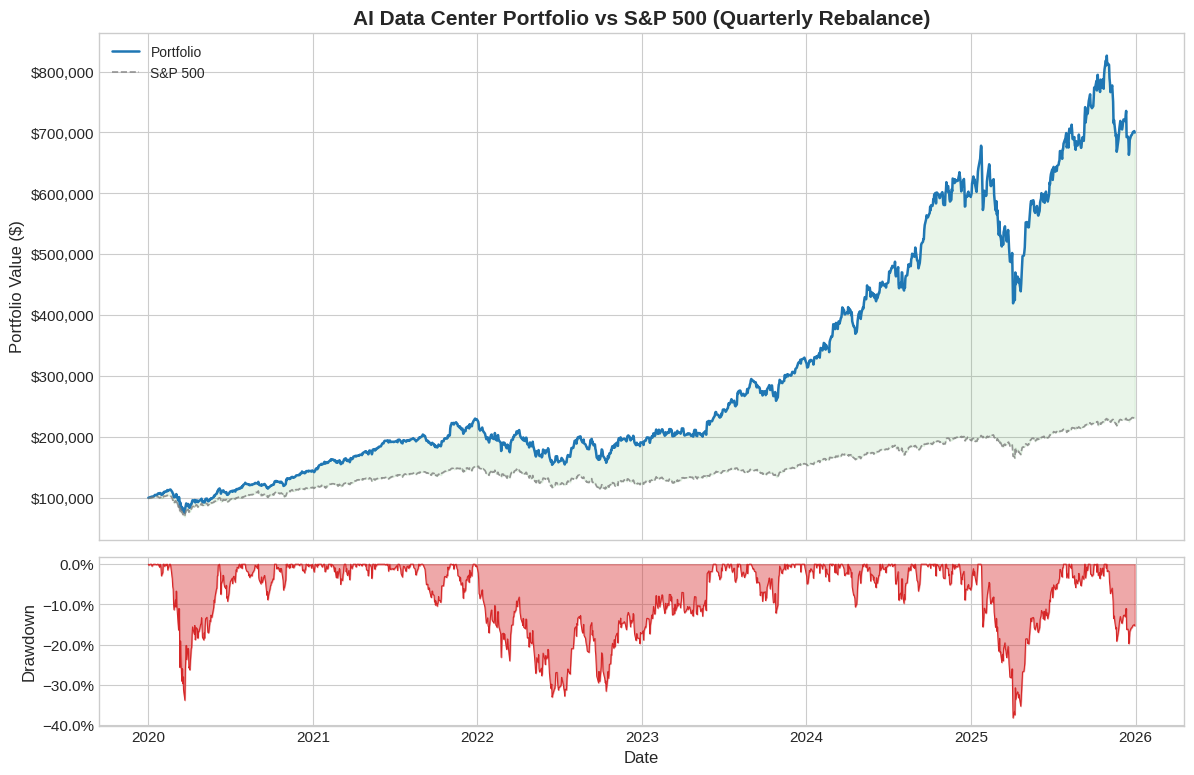

In [11]:
# === Equity Curve ===
Visualizer.plot_equity_curve(
    results, benchmark_prices,
    title='AI Data Center Portfolio vs S&P 500 (Quarterly Rebalance)'
)

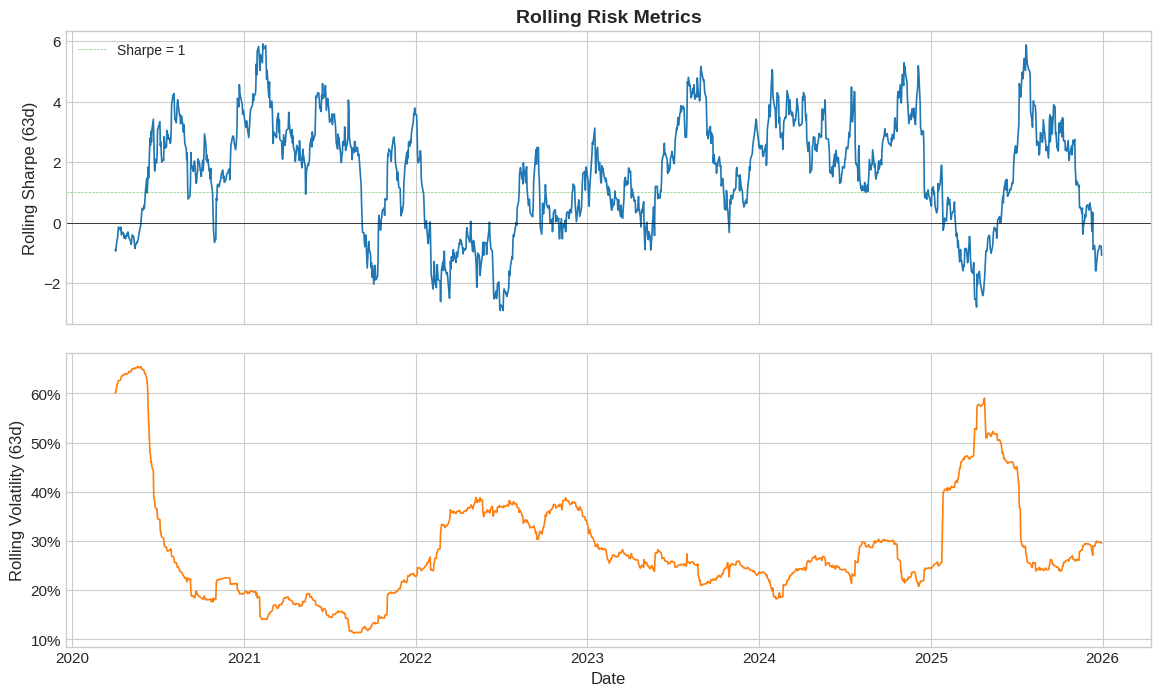

In [12]:
# === Rolling Risk Metrics ===
Visualizer.plot_rolling_metrics(results, rf_rate=config.risk_free_rate)

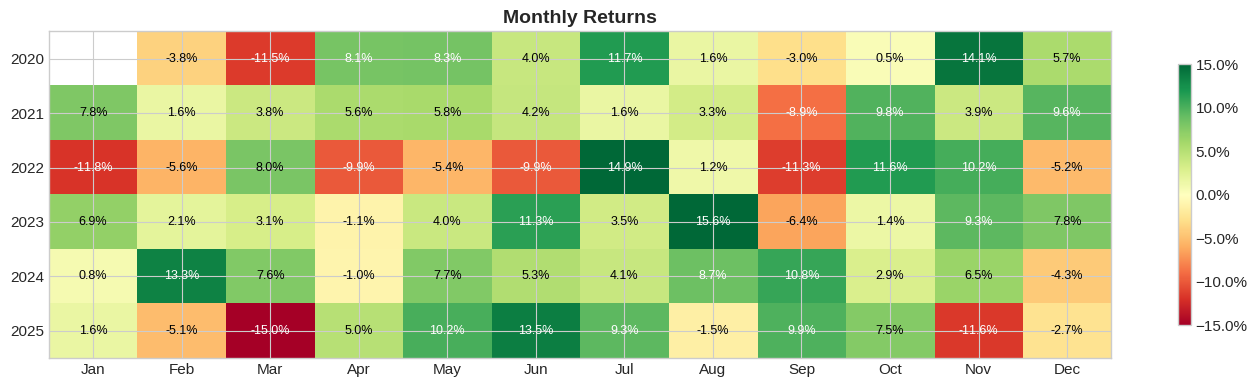

In [13]:
# === Monthly Returns Heatmap ===
Visualizer.plot_monthly_heatmap(results['portfolio_value'])

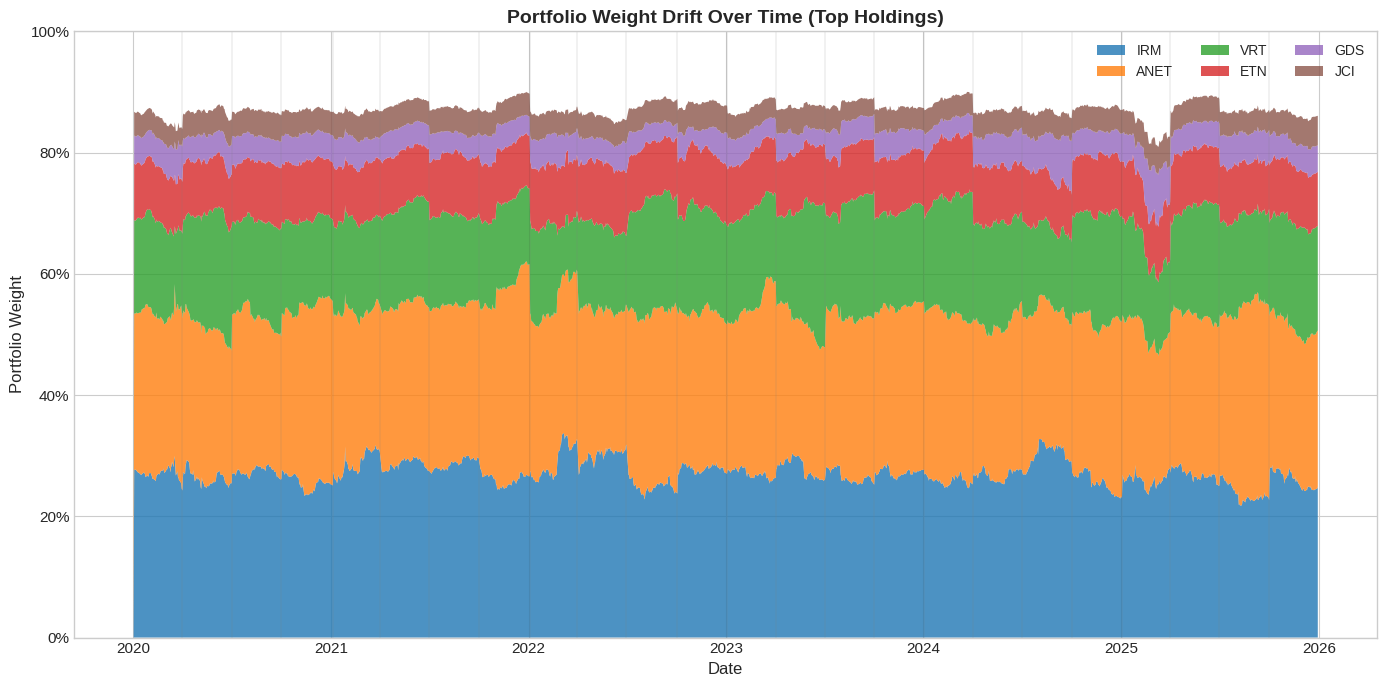

In [14]:
# === Weight Drift ===
Visualizer.plot_weight_drift(engine, list(TARGET_WEIGHTS.keys()))

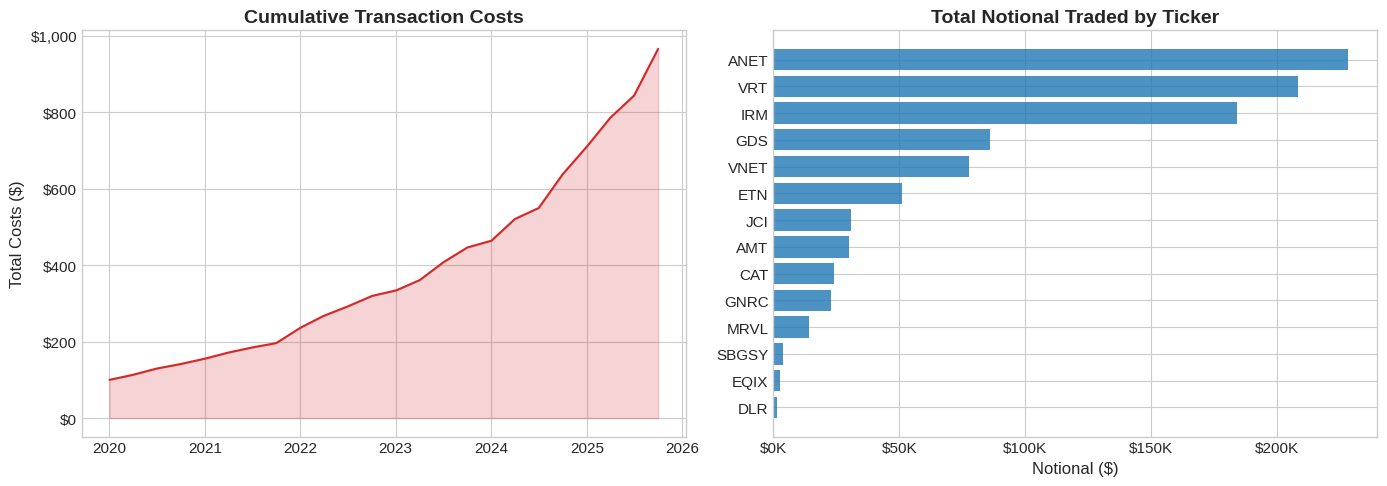

In [15]:
# === Trade Analysis ===
Visualizer.plot_trade_analysis(trade_log)

In [16]:
# === Top Drawdown Periods ===
top_dd = RiskAnalytics.top_drawdowns(results['portfolio_value'], n=5)
print('Top 5 Drawdown Periods:')
top_dd

Top 5 Drawdown Periods:


,Depth,Peak Date,Trough Date,Recovery Date,Days to Trough,Days to Recovery
0,-0.381763,2025-01-23,2025-04-04,2025-07-25,71,112
1,-0.337972,2020-02-20,2020-03-23,2020-06-08,32,77
2,-0.330162,2021-12-27,2022-06-16,2023-06-09,171,358
3,-0.197279,2025-10-29,2025-12-17,Ongoing,49,N/A
4,-0.121499,2023-09-01,2023-10-26,2023-11-14,55,19


<a id='9'></a>
## 9. Strategy comparison and cost sensitivity

All five rules now run on identical data through identical execution. Any difference in outcome is attributable to the rule.

Two warnings on how to read what follows.

First, this is five strategies tested on one sample, and the best of five is reported. The expected maximum Sharpe ratio across $N$ independent trials grows roughly like $\sqrt{2 \ln N}$ even when every underlying strategy has zero true edge, so the winner's margin over the others is partly a selection effect and not entirely skill. With $N = 5$ the inflation is modest, but it is not zero, and the correct way to handle it is a deflated Sharpe ratio rather than a sentence of caution. The companion project on this portfolio implements that deflation; this notebook does not, and the ranking here should be read as suggestive.

Second, several of the rules carry free parameters that were chosen rather than fitted: the 5% drift band, the 63-day momentum lookback, the 20% volatility target. Each one is a dimension along which the result could have been improved after the fact. I have not tuned them, but the reader has no way to verify that from the notebook alone, which is itself an argument for pre-registering parameter grids before running anything.

The cost sensitivity sweep then varies commission from 0 to 100 bps for the quarterly calendar rule. It asks a narrower question than it might appear to: not whether the ranking between rules survives realistic costs, but how much of the quarterly rule's own result depends on the cost assumption.

In [17]:
# === Run All Strategies ===

strategies = {
    'Buy & Hold': {
        'fn': strategy_buy_and_hold,
        'params': {'target_weights': TARGET_WEIGHTS}
    },
    'Monthly Rebalance': {
        'fn': strategy_calendar_rebalance,
        'params': {'target_weights': TARGET_WEIGHTS, 'frequency': 'monthly'}
    },
    'Quarterly Rebalance': {
        'fn': strategy_calendar_rebalance,
        'params': {'target_weights': TARGET_WEIGHTS, 'frequency': 'quarterly'}
    },
    'Annual Rebalance': {
        'fn': strategy_calendar_rebalance,
        'params': {'target_weights': TARGET_WEIGHTS, 'frequency': 'annually'}
    },
    'Threshold 5%': {
        'fn': strategy_threshold_rebalance,
        'params': {'target_weights': TARGET_WEIGHTS, 'threshold': 0.05}
    },
    'Momentum Overlay (3mo)': {
        'fn': strategy_momentum_overlay,
        'params': {'target_weights': TARGET_WEIGHTS, 'frequency': 'monthly',
                   'lookback_days': 63}
    },
    'Vol Target 20%': {
        'fn': strategy_vol_target,
        'params': {'target_weights': TARGET_WEIGHTS, 'frequency': 'monthly',
                   'target_vol': 0.20, 'vol_lookback': 63}
    },
}

all_results = {}
comparison_metrics = []

for name, strat in strategies.items():
    eng = BacktestEngine(config)
    res = eng.run(asset_prices, strat['fn'], strat['params'])
    all_results[name] = res
    
    tl = eng.get_trade_log()
    port_vals = res['portfolio_value']
    rets = res['daily_return'].dropna()
    mdd, _, _ = PerformanceAnalytics.max_drawdown(port_vals)
    
    comparison_metrics.append({
        'Strategy': name,
        'Total Return': f"{PerformanceAnalytics.total_return(port_vals):.1%}",
        'CAGR': f"{PerformanceAnalytics.cagr(port_vals):.1%}",
        'Ann. Vol': f"{PerformanceAnalytics.annualized_vol(rets):.1%}",
        'Sharpe': f"{PerformanceAnalytics.sharpe_ratio(rets, config.risk_free_rate):.2f}",
        'Sortino': f"{PerformanceAnalytics.sortino_ratio(rets, config.risk_free_rate):.2f}",
        'Max DD': f"{mdd:.1%}",
        'Calmar': f"{PerformanceAnalytics.calmar_ratio(port_vals):.2f}",
        'Trades': len(tl),
        'Costs': f"${tl['cost'].sum():,.0f}" if not tl.empty else '$0',
        'Final Value': f"${port_vals.iloc[-1]:,.0f}",
    })

comparison_df = pd.DataFrame(comparison_metrics).set_index('Strategy')
print('Strategy Comparison:')
comparison_df

Strategy Comparison:


,Total Return,CAGR,Ann. Vol,Sharpe,Sortino,Max DD,Calmar,Trades,Costs,Final Value
Strategy,,,,,,,,,,
Buy & Hold,578.9%,37.7%,33.3%,0.98,1.25,-47.3%,0.80,14,$100,"$677,925"
Monthly Rebalance,592.6%,38.1%,30.6%,1.05,1.36,-38.4%,0.99,833,"$1,535","$691,599"
Quarterly Rebalance,600.8%,38.4%,30.6%,1.06,1.37,-38.2%,1.01,298,$965,"$699,776"
Annual Rebalance,601.5%,38.4%,30.7%,1.06,1.38,-37.8%,1.02,81,$462,"$700,439"
Threshold 5%,640.5%,39.7%,30.6%,1.09,1.41,-36.9%,1.08,294,"$1,118","$739,411"
Momentum Overlay (3mo),388.6%,30.3%,33.6%,0.81,1.00,-50.1%,0.60,718,"$10,192","$487,823"
Vol Target 20%,312.9%,26.7%,23.4%,0.92,1.14,-34.0%,0.79,821,"$1,539","$412,290"


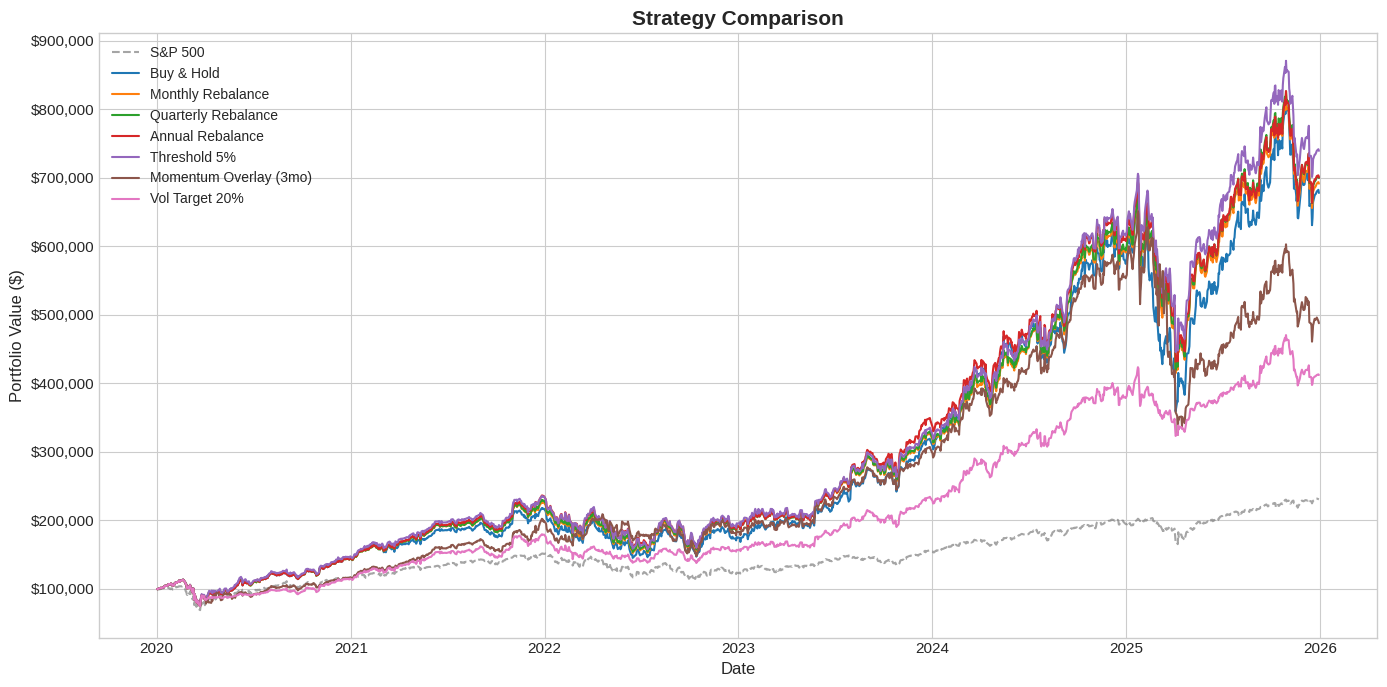

In [18]:
# === Visual Comparison ===
Visualizer.plot_strategy_comparison(all_results, benchmark_prices,
                                     config.initial_capital)

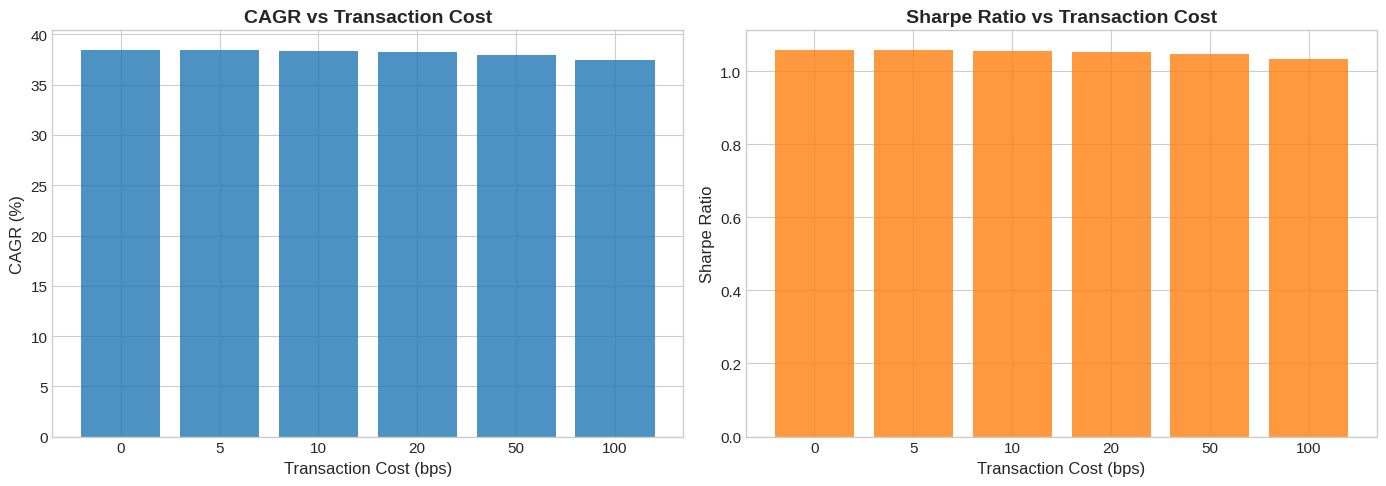

,Cost (bps),CAGR,Sharpe,Total Costs,Final Value
0,0,0.3848,1.0586,0.0000,703790.3621
1,5,0.3844,1.0574,483.7201,701922.1598
2,10,0.3839,1.0561,965.4861,699776.2354
3,20,0.3829,1.0535,1923.6677,695768.7067
4,50,0.3800,1.0460,4755.0185,683914.2407
5,100,0.3750,1.0332,9327.2371,664253.5351


In [19]:
# === Transaction Cost Sensitivity ===
# How sensitive is the quarterly strategy to transaction costs?

cost_levels = [0, 5, 10, 20, 50, 100]  # bps
cost_sensitivity = []

for cost_bps in cost_levels:
    cfg = BacktestConfig(
        initial_capital=config.initial_capital,
        transaction_cost_bps=cost_bps,
        slippage_bps=cost_bps // 2,  # slippage scales roughly with cost
        risk_free_rate=config.risk_free_rate,
    )
    eng = BacktestEngine(cfg)
    res = eng.run(asset_prices, strategy_calendar_rebalance,
                  {'target_weights': TARGET_WEIGHTS, 'frequency': 'quarterly'})
    
    port_vals = res['portfolio_value']
    rets = res['daily_return'].dropna()
    tl = eng.get_trade_log()
    
    cost_sensitivity.append({
        'Cost (bps)': cost_bps,
        'CAGR': PerformanceAnalytics.cagr(port_vals),
        'Sharpe': PerformanceAnalytics.sharpe_ratio(rets, config.risk_free_rate),
        'Total Costs': tl['cost'].sum() if not tl.empty else 0,
        'Final Value': port_vals.iloc[-1],
    })

cost_df = pd.DataFrame(cost_sensitivity)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(cost_df['Cost (bps)'].astype(str), cost_df['CAGR'] * 100,
            color=COLORS['primary'], alpha=0.8)
axes[0].set_title('CAGR vs Transaction Cost', fontweight='bold')
axes[0].set_xlabel('Transaction Cost (bps)')
axes[0].set_ylabel('CAGR (%)')

axes[1].bar(cost_df['Cost (bps)'].astype(str), cost_df['Sharpe'],
            color=COLORS['secondary'], alpha=0.8)
axes[1].set_title('Sharpe Ratio vs Transaction Cost', fontweight='bold')
axes[1].set_xlabel('Transaction Cost (bps)')
axes[1].set_ylabel('Sharpe Ratio')

plt.tight_layout()
plt.show()

cost_df.round(4)

### What the comparison shows

**Rebalancing frequency barely matters.** Monthly, quarterly and annual calendar rules land within 0.01 of each other in Sharpe ratio, with monthly paying over three times the costs of annual for nothing. The threshold rule comes out best at 1.09, which is the best of five and should be discounted accordingly.

**Rebalancing does reduce drawdown.** Buy and hold drew down 47% against roughly 38% for the calendar rules, because without rebalancing the winners grow into a larger share of the book exactly when they are most extended.

**The momentum overlay is the worst rule here**, with a Sharpe ratio of 0.81, a 50% drawdown and ten times the costs of the calendar rules. This is the concentration problem described in section 4: zeroing out falling names and redistributing their weight piles the portfolio into whatever survived, at the moment correlations rise.

**Volatility targeting cut the drawdown to 34% and the Sharpe ratio to 0.92.** Some of that shortfall is the engine paying zero interest on the cash this rule holds, so the comparison understates it, but not by enough to reverse the ranking.

**Costs are not what decides the quarterly rule.** Moving from 0 to 100 bps commission lowers its Sharpe ratio from 1.06 to 1.03. At quarterly frequency the turnover is too low for the fee schedule to matter; the result rests on the weights.

**The headline numbers should not be quoted.** A 38% CAGR and 601% total return come from weights optimised over almost the same window they are tested on, as set out in section 1. What this notebook establishes is how the rules compare given a set of weights, not that the weights were good.

<a id='10'></a>
## 10. Export

Results are written to CSV so they can be picked up by downstream analysis without re-running the backtest. The trade log in particular is the audit trail: every position in the final equity curve can be traced back to the fills that produced it.


In [20]:
# === Export to CSV ===
output_dir = './backtest_results'
os.makedirs(output_dir, exist_ok=True)

# Portfolio time series
results.to_csv(f'{output_dir}/portfolio_timeseries.csv')

# Trade log
if not trade_log.empty:
    trade_log.to_csv(f'{output_dir}/trade_log.csv', index=False)

# Strategy comparison
comparison_df.to_csv(f'{output_dir}/strategy_comparison.csv')

# Performance report
report.to_csv(f'{output_dir}/performance_report.csv')

# Monthly returns
monthly_table = RiskAnalytics.monthly_returns_table(results['portfolio_value'])
monthly_table.to_csv(f'{output_dir}/monthly_returns.csv')

print(f'All results exported to {output_dir}/')
print('Files:')
for f in os.listdir(output_dir):
    print(f'  {f}')

All results exported to ./backtest_results/
Files:
  monthly_returns.csv
  performance_report.csv
  portfolio_timeseries.csv
  strategy_comparison.csv
  trade_log.csv


---

## Architecture

```
backtesting_engine.ipynb
|
├── DataLoader            Loads the frozen price snapshot, falls back to live download
├── BacktestEngine        Day-by-day portfolio simulator
│   ├── run()             Main loop: mark to market, query strategy, rebalance, record
│   ├── _rebalance()      Order generation, sells before buys, cost application
│   └── get_trade_log()   Full fill-level audit trail
├── Strategies            Five rules behind one interface
├── PerformanceAnalytics  Return and risk-adjusted return metrics
├── RiskAnalytics         Drawdown decomposition, rolling estimates
└── Visualizer            Five diagnostic charts
```

## What I would add next

The engine currently has no notion of a risk-free rate on cash, which biases every strategy that holds a cash balance. Accruing the overnight rate on idle cash is a small change and would materially alter the standing of the volatility-targeted rule.

Beyond that, the natural extensions are a market impact model with size dependence rather than a flat slippage constant, and walk-forward parameter estimation so that the drift band and lookback windows are fitted on data preceding the period they are applied to rather than chosen once for the whole sample.
